# **Лабораторная работа №2.2**

## Реализация алгоритма полиномиальной регрессии на Scikit-Learn

### Описание задачи

1. Для выполнения используя  библиотека Scikit-Learn
2. Реализовать метод полиномиальной регрессии для заданного набора данных  используя различные степени полиномов (не менее 3х)
3. Отрисовать данные и регрессионные кривые на одном графике (использовать разные цвета с легендой).
4. Выбрать лучшую из полученных моделей используя метрики  MSE, R2, MAPE. 
5. Метрики для всех моделей собрать в таблицу
6. Сделать вывод по работе и обьяснить выбор степени полинома
* попробовать для данного набора данных применить линейную регрессию, нарисовать ее совместно с кривыми посчитать метрики


In [15]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
import matplotlib.pyplot as plt

### 1. Загрузка и обработка данных 

In [2]:
data = pd.read_csv('lab2_2_DS.csv')

In [3]:
data.head()

,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


In [4]:
data.describe()

,Temperature (°C),Ice Cream Sales (units)
count,49.000000,49.000000
mean,0.271755,15.905308
std,2.697672,12.264682
min,-4.662263,0.328626
25%,-2.111870,4.857988
50%,0.688781,12.615181
75%,2.784836,25.142082
max,4.899032,41.842986


In [28]:
X = data['Temperature (°C)'].values          
y = data['Ice Cream Sales (units)'].values   

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

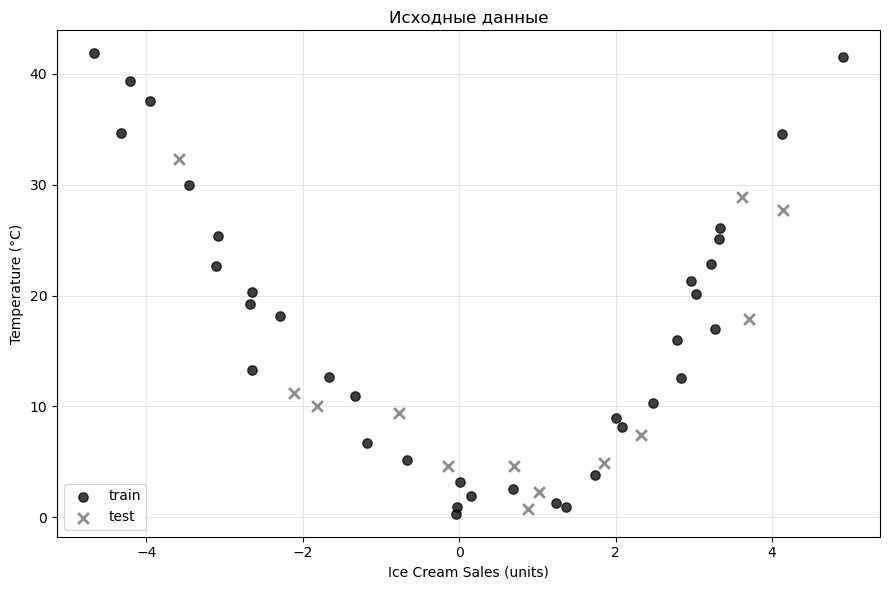

In [29]:
plt.figure(figsize=(9, 6))

plt.scatter(X_train, y_train, color="black", alpha=0.75, s=45,
                label="train", zorder=3)
plt.scatter(X_test, y_test, color="gray", alpha=0.9, s=60,
                marker="x", linewidths=2, label="test", zorder=3)

plt.xlabel('Ice Cream Sales (units)')
plt.ylabel("Temperature (°C)")
plt.title(f"Исходные данные")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 2. Реализация моделей полиномиальной регрессии

In [30]:
# Создание дополнительных признаков для полиномиальной регрессии
def polynomial_features(x, degree):
    x = np.asarray(x).ravel()
    return np.column_stack([x ** k for k in range(1, degree + 1)])

In [31]:
degrees = [1, 2, 3, 4, 5, 6]
models, metrics = {}, []

for d in degrees:
    Xtr = polynomial_features(X_train, d)
    Xte = polynomial_features(X_test, d)
    model = LinearRegression().fit(Xtr, y_train)
    y_pred = model.predict(Xte)
    models[d] = model
    metrics.append({
        "Степень": d,
        "MSE_train": mean_squared_error(y_train, model.predict(Xtr)),
        "MSE_test":  mean_squared_error(y_test, y_pred),
        "R2_test":   r2_score(y_test, y_pred),
        "MAPE_test": mean_absolute_percentage_error(y_test, y_pred),
    })

In [32]:
metrics_df = pd.DataFrame(metrics).round(3)
print(metrics_df.to_string(index=False))

 Степень  MSE_train  MSE_test  R2_test  MAPE_test
       1    148.409   132.898   -0.246      2.954
       2      8.998    13.892    0.870      0.614
       3      8.149    13.696    0.872      0.542
       4      6.109    16.173    0.848      0.432
       5      5.361    19.021    0.822      0.371
       6      5.026    20.441    0.808      0.356


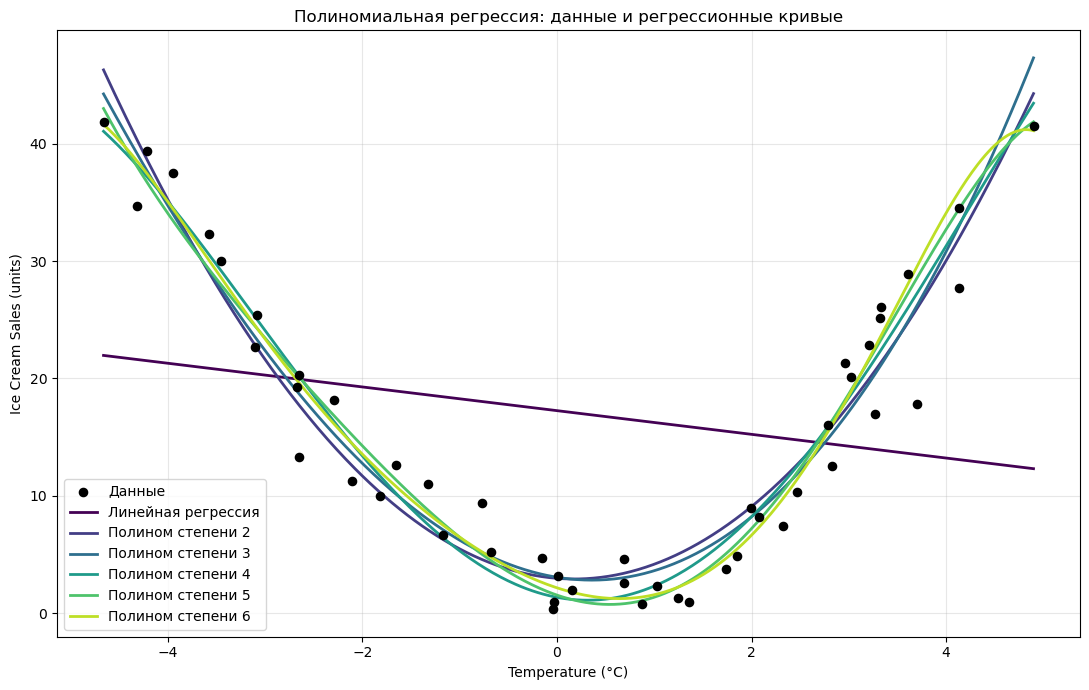

In [ ]:
x_grid = np.linspace(X.min(), X.max(), 500)
colors = plt.cm.viridis(np.linspace(0, 0.9, len(degrees)))

plt.figure(figsize=(11, 7))
plt.scatter(X, y, color="black", s=35, label="Данные", zorder=5)

for d, c in zip(degrees, colors):
    X_grid_poly = polynomial_features(x_grid, d) 
    y_grid = models[d].predict(X_grid_poly)
    label = "Линейная регрессия" if d == 1 else f"Полином степени {d}"
    plt.plot(x_grid, y_grid, color=c, lw=2, label=label)

plt.xlabel("Temperature (°C)")
plt.ylabel("Ice Cream Sales (units)")
plt.title("Полиномиальная регрессия: данные и регрессионные кривые")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3. Вывод

Линейная регрессия не подходит для задачи, так как из визуализации данных видно, что зависимость нелинейная. Уже полином 2-й степени резко улучшает качество и является наиболее подходящим для данной задачи. Полином 3-й степени даёт лучшие или близкие к лучшим метрики на тесте, хорошо описывая форму данных, но все же разница с полниомом 2-ой степени мала, а полином 2-ой степени лучшее отображает имеющуюся зависимость. Дальнейшее повышение степени (4–6) не улучшает тестовые метрики и не похожи на нашу зависимость, здесь можно наблюдать переобучение.